In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


## 2. Cargar el dataset

Sube un archivo CSV o Excel desde tu computadora.


In [3]:
filename = '/content/LI-Small_Trans.csv'
df = pd.read_csv(filename)
print("Archivo cargado:", filename)


Archivo cargado: /content/LI-Small_Trans.csv


## 3. Revisión rápida del dataset


In [4]:
df.head()


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:08,11,8000ECA90,11,8000ECA90,3195403.00,US Dollar,3195403.00,US Dollar,Reinvestment,0
1,2022/09/01 00:21,3402,80021DAD0,3402,80021DAD0,1858.96,US Dollar,1858.96,US Dollar,Reinvestment,0
2,2022/09/01 00:00,11,8000ECA90,1120,8006AA910,592571.00,US Dollar,592571.00,US Dollar,Cheque,0
3,2022/09/01 00:16,3814,8006AD080,3814,8006AD080,12.32,US Dollar,12.32,US Dollar,Reinvestment,0
4,2022/09/01 00:00,20,8006AD530,20,8006AD530,2941.56,US Dollar,2941.56,US Dollar,Reinvestment,0


In [5]:
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])
print("\nColumnas:")
print(df.columns.tolist())


Número de filas: 6924049
Número de columnas: 11

Columnas:
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6924049 entries, 0 to 6924048
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Timestamp           object 
 1   From Bank           int64  
 2   Account             object 
 3   To Bank             int64  
 4   Account.1           object 
 5   Amount Received     float64
 6   Receiving Currency  object 
 7   Amount Paid         float64
 8   Payment Currency    object 
 9   Payment Format      object 
 10  Is Laundering       int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 581.1+ MB


### Actividad rápida
Responde:
1. ¿Qué representa cada fila?
2. ¿Cuál es la unidad de registro?
3. ¿Cuál es la variable objetivo?
4. ¿Qué identificador o combinación de variables debería ser única?


1. **¿Qué representa cada fila?**
    Cada fila representa una transacción financiera única.
2. **¿Cuál es la unidad de registro?**
    La unidad de registro es una transacción individual.
3. **¿Cuál es la variable objetivo?**
    La variable objetivo es `Is Laundering`, que indica si una transacción es un caso de lavado de dinero (0 para no, 1 para sí).
4. **¿Qué identificador o combinación de variables debería ser única?**
    Idealmente, cada transacción debería tener un identificador único. En ausencia de un ID de transacción explícito, una combinación de `Timestamp`, `From Bank`, `Account`, `To Bank`, `Account.1`, `Amount Received`, y `Payment Format` podría considerarse una clave para identificar una transacción única.

# 4. Completitud: valores nulos

Primero veremos la cantidad y porcentaje de nulos por variable.


In [7]:
null_count = df.isnull().sum()
null_count.sort_values(ascending=False)


,0
Timestamp,0
From Bank,0
Account,0
To Bank,0
Account.1,0
Amount Received,0
Receiving Currency,0
Amount Paid,0
Payment Currency,0
Payment Format,0


In [8]:
null_percentage = (df.isnull().mean() * 100).sort_values(ascending=False)
null_percentage


,0
Timestamp,0.0
From Bank,0.0
Account,0.0
To Bank,0.0
Account.1,0.0
Amount Received,0.0
Receiving Currency,0.0
Amount Paid,0.0
Payment Currency,0.0
Payment Format,0.0


In [9]:
null_report = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Porcentaje_nulos": (df.isnull().mean() * 100).round(2)
}).sort_values("Porcentaje_nulos", ascending=False)

null_report


,Nulos,Porcentaje_nulos
Timestamp,0,0.0
From Bank,0,0.0
Account,0,0.0
To Bank,0,0.0
Account.1,0,0.0
Amount Received,0,0.0
Receiving Currency,0,0.0
Amount Paid,0,0.0
Payment Currency,0,0.0
Payment Format,0,0.0


### Porcentaje de nulos de una sola variable
Cambia `nombre_variable` por una columna real.


In [10]:
nombre_variable = "Timestamp"

if nombre_variable in df.columns:
    null_percentage_one = df[nombre_variable].isnull().mean() * 100
    print(f"Porcentaje de nulos en {nombre_variable}: {null_percentage_one:.2f}%")
else:
    print("Reemplaza 'SGC' por el nombre de una columna existente.")

Porcentaje de nulos en Timestamp: 0.00%


### Actividad 1 – Completitud

**Hallazgos:**
- **Variable con más nulos:** No se encontraron variables con valores nulos en el dataset.
- **Porcentaje:** 0% en todas las columnas.
- **Posible causa:** Los datos en el dataset `df` están completos. Esto podría indicar un proceso de limpieza previo o que la fuente de datos garantiza la completitud.
- **Posible impacto:** No hay impacto negativo directo por falta de completitud, lo cual es favorable para el análisis. Simplifica el preprocesamiento al no requerir manejo de valores faltantes.

> No eliminar ni reemplazar todavía. (Ya no es necesario, el dataset está completo.)

# 5. Unicidad: Registros duplicados


In [11]:
duplicate_count = df.duplicated().sum()
print("Duplicados completos:", duplicate_count)


Duplicados completos: 8


In [12]:
df[df.duplicated(keep=False)].head(20)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
676694,2022/09/01 05:03,21260,8085A09D1,72146,81AB967E1,0.000001,Bitcoin,0.000001,Bitcoin,Bitcoin,0
676696,2022/09/01 05:03,21260,8085A09D1,72146,81AB967E1,0.000001,Bitcoin,0.000001,Bitcoin,Bitcoin,0
790828,2022/09/01 07:44,231616,814E45511,171546,81B324AC1,0.000001,Bitcoin,0.000001,Bitcoin,Bitcoin,0
790830,2022/09/01 07:44,231616,814E45511,171546,81B324AC1,0.000001,Bitcoin,0.000001,Bitcoin,Bitcoin,0
2027614,2022/09/02 11:09,28335,804B468F1,171669,81BBCDAB1,0.000007,Bitcoin,0.000007,Bitcoin,Bitcoin,0
2027616,2022/09/02 11:09,28335,804B468F1,171669,81BBCDAB1,0.000007,Bitcoin,0.000007,Bitcoin,Bitcoin,0
3482551,2022/09/05 12:44,22661,80D016C81,269294,81A245E81,0.000005,Bitcoin,0.000005,Bitcoin,Bitcoin,0
3482553,2022/09/05 12:44,22661,80D016C81,269294,81A245E81,0.000005,Bitcoin,0.000005,Bitcoin,Bitcoin,0
4180129,2022/09/06 14:16,19970,804E44F11,169489,8197DC971,0.000001,Bitcoin,0.000001,Bitcoin,Bitcoin,0
4180131,2022/09/06 14:16,19970,804E44F11,169489,8197DC971,0.000001,Bitcoin,0.000001,Bitcoin,Bitcoin,0


### Duplicados según una clave
Cambia `customer_id` por una columna de tu dataset.


In [13]:
clave = "Account"

if clave in df.columns:
    print(f"Registros repetidos considerando '{clave}':")
    print(df.duplicated(subset=[clave]).sum())
else:
    print(f"La columna '{clave}' no existe. Modifica la variable 'clave'.")

Registros repetidos considerando 'Account':
6242768


### Actividad 2 – Unicidad

**1. ¿Cuántos duplicados completos existen?**
    Se encontraron **8 duplicados completos** en el dataset, donde todas las columnas son idénticas para esos registros.

**2. ¿Qué variable o combinación debería identificar un registro?**
    Para identificar una transacción única, una combinación de variables como `Timestamp`, `From Bank`, `Account`, `To Bank`, `Account.1`, `Amount Received`, y `Payment Format` sería más apropiada que una sola columna.

**3. ¿Los identificadores repetidos son realmente errores?**
    - Para los **8 duplicados completos**: Podrían ser errores de entrada de datos, problemas en la extracción o incluso transacciones idénticas que ocurrieron en el mismo instante (aunque esto último es raro).
    - Para la columna 'Account' (que mostró más de 6 millones de repeticiones): No es un error, ya que una misma cuenta puede participar en múltiples transacciones. Es un comportamiento esperado en un dataset de transacciones.

**4. ¿Qué contexto necesitas para confirmarlo?**
    Para los 8 duplicados completos, sería crucial consultar con los dueños de los datos o la fuente para entender la naturaleza de esos registros. Esto permitiría determinar si son válidos o si requieren algún tipo de limpieza o desduplicación. Para las cuentas repetidas, no se requiere un contexto adicional ya que su repetición es normal.

# 6. Consistencia: Variables

---

categóricas


In [14]:
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Variables categóricas:")
print(categorical_columns)


Variables categóricas:
['Timestamp', 'Account', 'Account.1', 'Receiving Currency', 'Payment Currency', 'Payment Format']


In [15]:
variable_categorica = "Receiving Currency"

if variable_categorica in df.columns:
    print(f"Análisis de consistencia para la variable: {variable_categorica}")
    display(df[variable_categorica].value_counts(dropna=False))
    print("\nValores únicos:")
    print(df[variable_categorica].unique())
    print("\nCantidad de valores únicos:", df[variable_categorica].nunique(dropna=False))
else:
    print(f"La columna '{variable_categorica}' no existe. Por favor, selecciona una variable categórica válida de la lista: {categorical_columns}")

Análisis de consistencia para la variable: Receiving Currency


,count
Receiving Currency,
US Dollar,2537242
Euro,1596407
Yuan,474978
Rupee,344237
Bitcoin,313196
Saudi Riyal,261882
Australian Dollar,213905
Yen,211631
Brazil Real,202717



Valores únicos:
['US Dollar' 'Euro' 'Bitcoin' 'Yuan' 'Yen' 'UK Pound' 'Brazil Real'
 'Australian Dollar' 'Rupee' 'Ruble' 'Canadian Dollar' 'Mexican Peso'
 'Swiss Franc' 'Shekel' 'Saudi Riyal']

Cantidad de valores únicos: 15


In [ ]:
variable_categorica = "Región"

if variable_categorica in df.columns:
    display(df[variable_categorica].value_counts(dropna=False))
    print("\nValores únicos:")
    print(df[variable_categorica].unique())
    print("\nCantidad de valores únicos:", df[variable_categorica].nunique(dropna=False))
else:
    print("Reemplaza 'Región' por una variable categórica existente.")


### Actividad 3 – Consistencia
Selecciona 3 variables categóricas y documenta:
- variable;
- problema encontrado;
- evidencia.

Ejemplo: `ciudad` → Lima / LIMA / lima.


### Actividad 3 – Consistencia

**1. Variable: Receiving Currency**
*   **Problema encontrado:** Ninguno. Los valores están estandarizados (ej. 'US Dollar', 'Euro') sin variaciones de capitalización o errores tipográficos.
*   **Evidencia:**
    ```
    Receiving Currency
    US Dollar            2537242
    Euro                 1596407
    Yuan                  474978
    Rupee                 344237
    Bitcoin               313196
    Saudi Riyal           261882
    Australian Dollar     213905
    Yen                   211631
    Brazil Real           202717
    Canadian Dollar       177966
    Shekel                177298
    Swiss Franc           140076
    UK Pound               98000
    Ruble                  89140
    Mexican Peso           85374
    ```
    Los valores únicos son claros y no presentan inconsistencias: `['US Dollar' 'Euro' 'Bitcoin' 'Yuan' 'Yen' 'UK Pound' 'Brazil Real' 'Australian Dollar' 'Rupee' 'Ruble' 'Canadian Dollar' 'Mexican Peso' 'Swiss Franc' 'Shekel' 'Saudi Riyal']`.

In [16]:
variable_categorica_2 = "Payment Currency"

if variable_categorica_2 in df.columns:
    print(f"Análisis de consistencia para la variable: {variable_categorica_2}")
    display(df[variable_categorica_2].value_counts(dropna=False))
    print("\nValores únicos:")
    print(df[variable_categorica_2].unique())
    print("\nCantidad de valores únicos:", df[variable_categorica_2].nunique(dropna=False))
else:
    print(f"La columna '{variable_categorica_2}' no existe. Por favor, selecciona una variable categórica válida de la lista: {categorical_columns}")

Análisis de consistencia para la variable: Payment Currency


,count
Payment Currency,
US Dollar,2553887
Euro,1595859
Yuan,483603
Rupee,340641
Bitcoin,309240
Saudi Riyal,257948
Australian Dollar,211155
Yen,210125
Brazil Real,199840



Valores únicos:
['US Dollar' 'Euro' 'Bitcoin' 'Yuan' 'Yen' 'UK Pound' 'Brazil Real'
 'Australian Dollar' 'Rupee' 'Ruble' 'Canadian Dollar' 'Mexican Peso'
 'Swiss Franc' 'Shekel' 'Saudi Riyal']

Cantidad de valores únicos: 15


**2. Variable: Payment Currency**
*   **Problema encontrado:** Ninguno. Los valores están estandarizados y no presentan variaciones de capitalización o errores tipográficos.
*   **Evidencia:**
    ```
    Payment Currency
    US Dollar            2553887
    Euro                 1595859
    Yuan                  483603
    Rupee                 340641
    Bitcoin               309240
    Saudi Riyal           257948
    Australian Dollar     211155
    Yen                   210125
    Brazil Real           199840
    Canadian Dollar       176069
    Shekel                174530
    Swiss Franc           138251
    UK Pound               99668
    Ruble                  88492
    Mexican Peso           84741
    ```
    Los valores únicos son claros y no presentan inconsistencias: `['US Dollar' 'Euro' 'Bitcoin' 'Yuan' 'Yen' 'UK Pound' 'Brazil Real' 'Australian Dollar' 'Rupee' 'Ruble' 'Canadian Dollar' 'Mexican Peso' 'Swiss Franc' 'Shekel' 'Saudi Riyal']`.

In [17]:
variable_categorica_3 = "Payment Format"

if variable_categorica_3 in df.columns:
    print(f"Análisis de consistencia para la variable: {variable_categorica_3}")
    display(df[variable_categorica_3].value_counts(dropna=False))
    print("\nValores únicos:")
    print(df[variable_categorica_3].unique())
    print("\nCantidad de valores únicos:", df[variable_categorica_3].nunique(dropna=False))
else:
    print(f"La columna '{variable_categorica_3}' no existe. Por favor, selecciona una variable categórica válida de la lista: {categorical_columns}")

Análisis de consistencia para la variable: Payment Format


,count
Payment Format,
Cheque,2503158
Credit Card,1780389
ACH,796581
Cash,655688
Reinvestment,650458
Bitcoin,309208
Wire,228567



Valores únicos:
['Reinvestment' 'Cheque' 'ACH' 'Credit Card' 'Wire' 'Cash' 'Bitcoin']

Cantidad de valores únicos: 7


# 7. Validez: Reglas del dominio


In [18]:
variable_numerica = "Amount Received"
limite_minimo = 0
limite_maximo = 120

if variable_numerica in df.columns:
    invalidos = df[
        (df[variable_numerica] < limite_minimo) |
        (df[variable_numerica] > limite_maximo)
    ]
    print("Cantidad de valores fuera del rango:", len(invalidos))
    display(invalidos.head(20))
else:
    print("Reemplaza 'REEMPLAZAR' por una variable numérica existente.")

Cantidad de valores fuera del rango: 5468863


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:08,11,8000ECA90,11,8000ECA90,3195403.00,US Dollar,3195403.00,US Dollar,Reinvestment,0
1,2022/09/01 00:21,3402,80021DAD0,3402,80021DAD0,1858.96,US Dollar,1858.96,US Dollar,Reinvestment,0
2,2022/09/01 00:00,11,8000ECA90,1120,8006AA910,592571.00,US Dollar,592571.00,US Dollar,Cheque,0
4,2022/09/01 00:00,20,8006AD530,20,8006AD530,2941.56,US Dollar,2941.56,US Dollar,Reinvestment,0
5,2022/09/01 00:24,12,8006ADD30,12,8006ADD30,6473.62,US Dollar,6473.62,US Dollar,Reinvestment,0
6,2022/09/01 00:17,11,800059120,1217,8006AD4E0,60562.00,US Dollar,60562.00,US Dollar,ACH,0
13,2022/09/01 00:08,394,80093BDB0,21414,80092A6C0,64335.00,US Dollar,64335.00,US Dollar,ACH,0
14,2022/09/01 00:04,1291,80092A730,1291,80092A730,3975.24,US Dollar,3975.24,US Dollar,Reinvestment,0
15,2022/09/01 00:20,1231,800B69730,11265,80092AC50,1986.00,US Dollar,1986.00,US Dollar,Cheque,0
16,2022/09/01 00:14,394,80093BDB0,394,80093BDB0,14903.78,US Dollar,14903.78,US Dollar,Reinvestment,0


### Importante
Un valor extraño no siempre es un error.
Por ejemplo, un monto negativo podría representar una devolución o reverso.


# 8. Posibles valores atípicos


In [19]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Variables numéricas:")
print(numeric_columns)


Variables numéricas:
['From Bank', 'To Bank', 'Amount Received', 'Amount Paid', 'Is Laundering']


In [20]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
From Bank,6924049.0,5.938718e+04,9.051700e+04,0.000000,219.00,14195.00,110682.00,3.769670e+05
To Bank,6924049.0,8.441702e+04,9.064562e+04,0.000000,11255.00,29640.00,148040.00,3.769670e+05
Amount Received,6924049.0,6.324067e+06,2.105371e+09,0.000001,174.21,1397.62,12296.33,3.644854e+12
Amount Paid,6924049.0,4.676036e+06,1.544099e+09,0.000001,175.38,1399.44,12226.87,3.644854e+12
Is Laundering,6924049.0,5.148722e-04,2.268495e-02,0.000000,0.00,0.00,0.00,1.000000e+00


## Método IQR
- Q1 = percentil 25
- Q3 = percentil 75
- IQR = Q3 - Q1
- Límite inferior = Q1 - 1.5 × IQR
- Límite superior = Q3 + 1.5 × IQR

> Un valor fuera de estos límites es un **posible outlier**, no necesariamente error.


In [22]:
variable_outlier = "Amount Received"

if variable_outlier in df.columns:
    serie = df[variable_outlier].dropna()

    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[variable_outlier] < lower_limit) |
        (df[variable_outlier] > upper_limit)
    ]

    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Límite inferior:", lower_limit)
    print("Límite superior:", upper_limit)
    print("Cantidad de posibles outliers:", len(outliers))
    print(f"Porcentaje: {len(outliers) / len(df) * 100:.2f}%")
    display(outliers.head(20))
else:
    print("Reemplaza 'REEMPLAZAR' por una variable numérica existente.")

Q1: 174.21
Q3: 12296.33
IQR: 12122.12
Límite inferior: -18008.97
Límite superior: 30479.510000000002
Cantidad de posibles outliers: 1200046
Porcentaje: 17.33%


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:08,11,8000ECA90,11,8000ECA90,3195403.00,US Dollar,3195403.00,US Dollar,Reinvestment,0
2,2022/09/01 00:00,11,8000ECA90,1120,8006AA910,592571.00,US Dollar,592571.00,US Dollar,Cheque,0
6,2022/09/01 00:17,11,800059120,1217,8006AD4E0,60562.00,US Dollar,60562.00,US Dollar,ACH,0
13,2022/09/01 00:08,394,80093BDB0,21414,80092A6C0,64335.00,US Dollar,64335.00,US Dollar,ACH,0
44,2022/09/01 00:29,1291,800B9BC30,1291,800B9BC30,59713.16,US Dollar,59713.16,US Dollar,Reinvestment,0
45,2022/09/01 00:22,12,800BA4BE0,1422,800B9BC80,111111.00,US Dollar,111111.00,US Dollar,Cheque,0
70,2022/09/01 00:11,11701,800BC6AF0,11701,800BC6AF0,1107318.59,US Dollar,1107318.59,US Dollar,Reinvestment,0
77,2022/09/01 00:21,21393,800BDE650,1120,800BCE950,5329268.00,US Dollar,5329268.00,US Dollar,Cheque,0
81,2022/09/01 00:23,349,800BC6CC0,1217,800BDE6A0,46720.00,US Dollar,46720.00,US Dollar,ACH,0
83,2022/09/01 00:18,20,800057660,11495,800BC8570,154661.00,US Dollar,154661.00,US Dollar,ACH,0


## Visualización


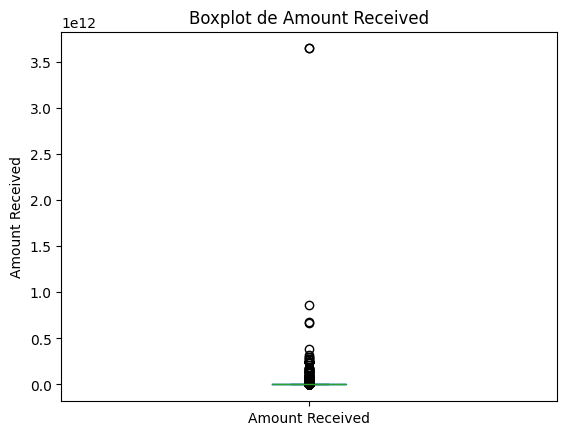

In [24]:
variable_grafico = "Amount Received"

if variable_grafico in df.columns:
    df[variable_grafico].plot(kind="box")
    plt.title(f"Boxplot de {variable_grafico}")
    plt.ylabel(variable_grafico)
    plt.show()
else:
    print("Reemplaza 'REEMPLAZAR' por una variable numérica existente.")

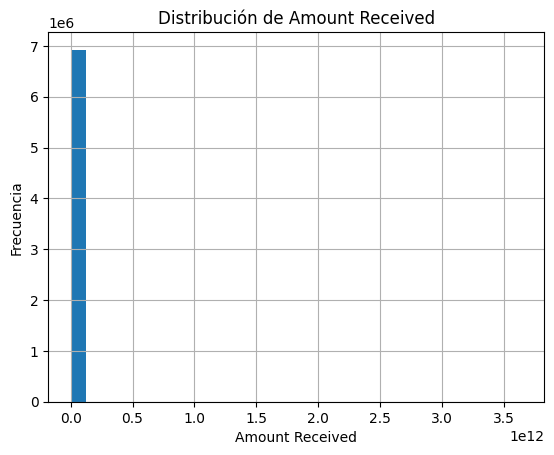

In [25]:
variable_histograma = "Amount Received"

if variable_histograma in df.columns:
    df[variable_histograma].dropna().hist(bins=30)
    plt.title(f"Distribución de {variable_histograma}")
    plt.xlabel(variable_histograma)
    plt.ylabel("Frecuencia")
    plt.show()
else:
    print("Reemplaza 'REEMPLAZAR' por una variable numérica existente.")

### Diferencia clave

**Error:** viola claramente una regla del dominio.
Ejemplo: `Amount Received` = -5,000 (un monto negativo en transacciones estándar que no permita reversos) o una fecha transaccional en el año 2099.

**Outlier válido:** valor extremo que podría ser real debido a la naturaleza del negocio.
Ejemplo: `Amount Received` = 3,644,854,000,000.00 (una transacción institucional o interbancaria legítima de gran volumen).

> **Outlier ≠ error**

# 9. Matriz de calidad

Tipos:
- Completitud
- Unicidad
- Consistencia
- Validez
- Exactitud

Severidad:
- Alta
- Media
- Baja


In [27]:
matriz_calidad = pd.DataFrame({
    "Variable": ["General", "General", "Amount Received", "Account", "Receiving/Payment Currency, Payment Format"],
    "Problema": ["No se encontraron valores nulos.", "8 registros duplicados completos.", "Gran cantidad de valores identificados como atípicos por IQR.", "No es un identificador único de transacción.", "No se encontraron inconsistencias (ej. typos, mayúsculas/minúsculas) en variables categóricas."],
    "Tipo_de_calidad": ["Completitud", "Unicidad", "Posibles valores atípicos", "Unicidad", "Consistencia"],
    "Evidencia": ["Todas las columnas tienen 0% de nulos.", "df.duplicated().sum() == 8.", "17.33% de los registros están fuera de los límites IQR.", "df.duplicated(subset=['Account']).sum() > 0. Esto es esperado.", "value_counts().unique() mostró valores limpios y estandarizados."],
    "Severidad": ["Baja", "Baja", "Media", "Baja", "Baja"]
})

matriz_calidad

,Variable,Problema,Tipo_de_calidad,Evidencia,Severidad
0,General,No se encontraron valores nulos.,Completitud,Todas las columnas tienen 0% de nulos.,Baja
1,General,8 registros duplicados completos.,Unicidad,df.duplicated().sum() == 8.,Baja
2,Amount Received,Gran cantidad de valores identificados como at...,Posibles valores atípicos,17.33% de los registros están fuera de los lím...,Media
3,Account,No es un identificador único de transacción.,Unicidad,df.duplicated(subset=['Account']).sum() > 0. E...,Baja
4,"Receiving/Payment Currency, Payment Format","No se encontraron inconsistencias (ej. typos, ...",Consistencia,value_counts().unique() mostró valores limpios...,Baja


# 10. Hallazgos y Problemas iniciales

Si han encontrado algun hallazgo, es momento de actualizar en tu ficha



# 11. Resumen automático de calidad


In [28]:
print("===== RESUMEN DEL DATASET =====")
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

print("\n===== NULOS =====")
print("Total de valores nulos:", int(df.isnull().sum().sum()))
print("\nTop 5 variables con mayor % de nulos:")
display((df.isnull().mean() * 100).sort_values(ascending=False).head(5).to_frame("% Nulos"))

print("\n===== DUPLICADOS =====")
print("Duplicados completos:", int(df.duplicated().sum()))

print("\n===== VARIABLES =====")
print("Numéricas:", len(df.select_dtypes(include=np.number).columns))
print("Categóricas:", len(df.select_dtypes(include=["object", "category"]).columns))


===== RESUMEN DEL DATASET =====
Filas: 6924049
Columnas: 11

===== NULOS =====
Total de valores nulos: 0

Top 5 variables con mayor % de nulos:


,% Nulos
Timestamp,0.0
From Bank,0.0
Account,0.0
To Bank,0.0
Account.1,0.0



===== DUPLICADOS =====
Duplicados completos: 8

===== VARIABLES =====
Numéricas: 5
Categóricas: 6


# 12. Conclusión

Sí podemos continuar con este dataset. No tiene valores nulos y las categorías revisadas no muestran problemas evidentes. Encontramos 8 filas duplicadas y, en `Amount Received`, 17,33 % de posibles valores atípicos según IQR. Antes de limpiar los datos, debemos revisar si los duplicados son transacciones distintas y si esos montos altos son válidos según la moneda y el tipo de operación. El límite de 120 usado en la prueba de validez no está justificado, así que no podemos considerar erróneos los montos que lo superan.

# 13. Entregable

- [ ] Carga del dataset
- [ ] Dimensiones
- [ ] Reporte de nulos
- [ ] Porcentaje de nulos
- [ ] Duplicados
- [ ] Revisión de variables categóricas
- [ ] Reglas de validez
- [ ] Estadística descriptiva
- [ ] Posibles outliers
- [ ] Matriz de calidad
- [ ] Update de Hallazgo y Problemas Iniciales
- [ ] Conclusión final

> **No realizar limpieza masiva todavía. Esta sesión se centra en detectar, medir, interpretar y documentar.**
